In [20]:
# ============================================================
#  Reflective-CXR | Phase B: Generative Fusion (Prototype)
#  Task: Stitch Adapted ViT to BioGPT & Train on IU-Xray
#  Storage: Institutional Google Drive
# ============================================================

!pip install -q transformers datasets torch torchvision accelerate kaggle tqdm scikit-learn matplotlib
print("Dependencies installed.")

from google.colab import drive
import os

drive.mount('/content/drive')

# Pointing to the exact ViT you just saved in Phase A
PHASE_A_ENCODER_DIR = '/content/drive/MyDrive/Thesis_CXR/phaseA_prototype_encoder/checkpoint_epoch_3'

# Where we will save the final, complete model
FINAL_MODEL_DIR = '/content/drive/MyDrive/Thesis_CXR/phaseB_final_model'
os.makedirs(FINAL_MODEL_DIR, exist_ok=True)
print("Storage directories linked.")

Dependencies installed.
Mounted at /content/drive
Storage directories linked.


In [4]:
import os
import torch
from google.colab import userdata

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if torch.cuda.is_available():
    print(f"Phase B Hardware locked: {torch.cuda.get_device_name(0)}")
else:
    raise SystemError("GPU NOT FOUND. Change runtime type to T4 GPU.")

os.environ['KAGGLE_USERNAME'] = userdata.get('KAGGLE_USERNAME')
os.environ['KAGGLE_KEY'] = userdata.get('KAGGLE_KEY')
print("Credentials loaded.")

Phase B Hardware locked: Tesla T4
Credentials loaded.


In [5]:
print("Downloading Indiana University Chest X-ray dataset...")
!kaggle datasets download -d raddar/chest-xrays-indiana-university
print("Unzipping...")
!unzip -q chest-xrays-indiana-university.zip -d iu_data
print("IU-Xray Text/Image pairs ready in local runtime.")

Dataset URL: https://www.kaggle.com/datasets/raddar/chest-xrays-indiana-university
License(s): Attribution-NonCommercial-NoDerivatives 4.0 International (CC BY-NC-ND 4.0)
100% 13.2G/13.2G [02:18<00:00, 102MB/s] 

Unzipping...
IU-Xray Text/Image pairs ready in local runtime.


In [9]:
import pandas as pd
from sklearn.model_selection import train_test_split

reports_df = pd.read_csv('/content/iu_data/indiana_reports.csv')
projections_df = pd.read_csv('/content/iu_data/indiana_projections.csv')

# Merge to link images to their text reports (Frontal X-rays only)
df_merged = pd.merge(projections_df, reports_df, on='uid')
df_frontal = df_merged[df_merged['projection'] == 'Frontal']

# Drop empty reports
df_frontal = df_frontal.dropna(subset=['findings']).reset_index(drop=True)

# Dynamically set sample size to avoid population overflow errors
max_samples = min(4000, len(df_frontal))
print(f"Total valid frontal X-rays found: {len(df_frontal)}")

df_sample = df_frontal.sample(max_samples, random_state=42)
train_text_df, val_text_df = train_test_split(df_sample, test_size=0.1, random_state=42)

print(f"Phase B Training pairs: {len(train_text_df)} | Validation pairs: {len(val_text_df)}")

Total valid frontal X-rays found: 3307
Phase B Training pairs: 2976 | Validation pairs: 331


In [12]:
!pip install -q sacremoses

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 897.5/897.5 kB 13.8 MB/s eta 0:00:00


In [21]:
import os
drive_path = '/content/drive/MyDrive/Thesis_CXR/phaseA_prototype_encoder/'

if os.path.exists(drive_path):
    print("Files found in your Phase A folder:")
    print(os.listdir(drive_path))
else:
    print("The entire phaseA_prototype_encoder folder is missing. Drive might not be mounted.")

Files found in your Phase A folder:
['checkpoint_epoch_1', 'checkpoint_epoch_2', 'checkpoint_epoch_3', 'checkpoint_epoch_4', 'checkpoint_epoch_5', 'checkpoint_epoch_6', 'checkpoint_epoch_7', 'checkpoint_epoch_8', 'checkpoint_epoch_9', 'checkpoint_epoch_10']


In [22]:
from torch.utils.data import Dataset, DataLoader
from transformers import ViTImageProcessor, AutoTokenizer
from PIL import Image
import os
import torch

print("Loading models (Bypassing local processor lookup)...")

# 1. Load the tokenizer for BioGPT
tokenizer = AutoTokenizer.from_pretrained("microsoft/biogpt", token=False)
tokenizer.pad_token = tokenizer.eos_token

# 2. Load the base Image Processor
processor = ViTImageProcessor.from_pretrained("google/vit-base-patch16-224")

# Re-declare your custom weights path for Cell 6
PHASE_A_ENCODER_DIR = '/content/drive/MyDrive/Thesis_CXR/phaseA_prototype_encoder/checkpoint_epoch_10'

# Safety check for Cell 6
if not os.path.exists(PHASE_A_ENCODER_DIR):
    print(f"\n WARNING: Cannot find {PHASE_A_ENCODER_DIR}.")
    print("Please check your Google Drive and ensure 'checkpoint_epoch_3' exists!")
else:
    print(f"\n Custom ViT weights located safely at: {PHASE_A_ENCODER_DIR}")

class IUXrayGenerativeDataset(Dataset):
    def __init__(self, dataframe, img_dir, tokenizer, processor, max_length=128):
        self.df = dataframe.reset_index(drop=True)
        self.img_dir = img_dir
        self.tokenizer = tokenizer
        self.processor = processor
        self.max_length = max_length

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        # Image Processing
        img_name = self.df.loc[idx, 'filename']
        img_path = os.path.join(self.img_dir, 'images/images_normalized', img_name)

        try:
            image = Image.open(img_path).convert('RGB')
        except Exception:
            image = Image.new('RGB', (224, 224), (0, 0, 0))

        pixel_values = self.processor(image, return_tensors="pt").pixel_values.squeeze()

        # Text Processing
        report_text = self.df.loc[idx, 'findings']
        encodings = self.tokenizer(
            report_text,
            padding="max_length",
            truncation=True,
            max_length=self.max_length,
            return_tensors="pt"
        )

        labels = encodings.input_ids.squeeze()
        labels[labels == self.tokenizer.pad_token_id] = -100

        return {"pixel_values": pixel_values, "labels": labels}

IMG_BASE_DIR = '/content/iu_data'

train_dataset = IUXrayGenerativeDataset(train_text_df, IMG_BASE_DIR, tokenizer, processor)
val_dataset = IUXrayGenerativeDataset(val_text_df, IMG_BASE_DIR, tokenizer, processor)

train_loader = DataLoader(train_dataset, batch_size=4, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=4, shuffle=False, num_workers=2, pin_memory=True)

print("Generative DataLoaders locked and ready.")

Loading models (Bypassing local processor lookup)...

 Custom ViT weights located safely at: /content/drive/MyDrive/Thesis_CXR/phaseA_prototype_encoder/checkpoint_epoch_10
Generative DataLoaders locked and ready.


In [25]:
from transformers import VisionEncoderDecoderModel, ViTModel, BioGptForCausalLM, AutoConfig

print("Stitching architectures together (Blueprint Override)...")

# 1. Load the Vision Encoder separately from your Drive
encoder = ViTModel.from_pretrained(PHASE_A_ENCODER_DIR)

# 2. Download the BioGPT blueprint (Config) and rewrite the rules
decoder_config = AutoConfig.from_pretrained("microsoft/biogpt")
decoder_config.is_decoder = True
decoder_config.add_cross_attention = True

# 3. Build the Text Decoder using our modified blueprint
decoder = BioGptForCausalLM.from_pretrained("microsoft/biogpt", config=decoder_config)

# 4. Manually clamp them together into a single VLM
model = VisionEncoderDecoderModel(encoder=encoder, decoder=decoder)

# 5. Configure the vocabulary and bridge tokens
model.config.decoder_start_token_id = tokenizer.bos_token_id
model.config.pad_token_id = tokenizer.pad_token_id
model.config.vocab_size = model.config.decoder.vocab_size

model = model.to(device)

total_params = sum(p.numel() for p in model.parameters()) / 1e6
print(f"Fusion Complete. Total VLM Parameters: {total_params:.1f}M")

Stitching architectures together (Blueprint Override)...


Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

ViTModel LOAD REPORT from: /content/drive/MyDrive/Thesis_CXR/phaseA_prototype_encoder/checkpoint_epoch_10
Key                 | Status  | 
--------------------+---------+-
pooler.dense.bias   | MISSING | 
pooler.dense.weight | MISSING | 

Notes:
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

The tied weights mapping and config for this model specifies to tie biogpt.embed_tokens.weight to output_projection.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning


Fusion Complete. Total VLM Parameters: 477.3M


In [26]:
import torch.optim as optim
from tqdm import tqdm

# We use CrossEntropy (handled internally by the model) to predict the next word
optimizer = optim.AdamW(model.parameters(), lr=1e-5)
scaler = torch.cuda.amp.GradScaler(enabled=torch.cuda.is_available())

EPOCHS = 10

print("Commencing Phase B Generative Training...")

for epoch in range(EPOCHS):
    model.train()
    running_loss = 0.0
    loop = tqdm(train_loader, desc=f"Epoch {epoch+1}/{EPOCHS} [Train Gen]")

    for batch in loop:
        pixel_values = batch["pixel_values"].to(device)
        labels = batch["labels"].to(device)

        optimizer.zero_grad()

        with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):
            # The model automatically handles the cross-attention and text loss
            outputs = model(pixel_values=pixel_values, labels=labels)
            loss = outputs.loss

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item()
        loop.set_postfix(loss=f"{loss.item():.4f}")

    avg_train_loss = running_loss / len(train_loader)
    print(f"\nEpoch {epoch+1} Text Generation Loss: {avg_train_loss:.4f}")

    # Save the massive fused model securely to Drive
    save_path = f"{FINAL_MODEL_DIR}/fused_model_epoch_{epoch+1}"
    model.save_pretrained(save_path)
    tokenizer.save_pretrained(save_path)
    print(f"Fused Model securely saved to Drive: {save_path}")

print("Phase B Complete. The VLM is fully trained and saved.")

/tmp/ipykernel_4322/4086145293.py:6: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=torch.cuda.is_available())


Commencing Phase B Generative Training...


Epoch 1/10 [Train Gen]:   0%|          | 0/744 [00:00<?, ?it/s]/tmp/ipykernel_4322/4086145293.py:23: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):
Epoch 1/10 [Train Gen]: 100%|██████████| 744/744 [06:12<00:00,  2.00it/s, loss=1.1832]


Epoch 1 Text Generation Loss: 1.6349


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Fused Model securely saved to Drive: /content/drive/MyDrive/Thesis_CXR/phaseB_final_model/fused_model_epoch_1


... (32 outputs left out)

Epoch 10/10 [Train Gen]: 100%|██████████| 744/744 [06:11<00:00,  2.00it/s, loss=0.4910]


Epoch 10 Text Generation Loss: 0.4714


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Fused Model securely saved to Drive: /content/drive/MyDrive/Thesis_CXR/phaseB_final_model/fused_model_epoch_10
Phase B Complete. The VLM is fully trained and saved.


Extracting a random test X-ray for AI generation...


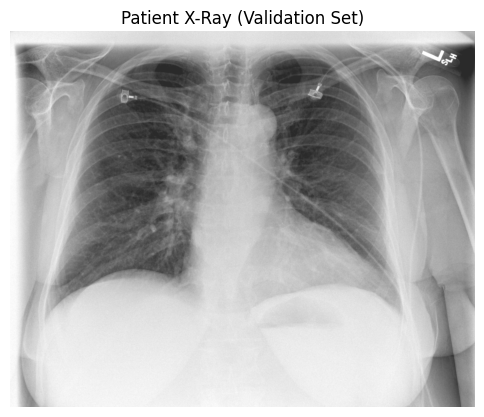


ACTUAL RADIOLOGIST REPORT:
The cardiac silhouette is near upper limits of normal in size. Pulmonary vasculature is normal in caliber. There is mild tortuosity of the descending thoracic aorta. The lungs are clear of focal airspace disease, pneumothorax, or pleural effusion. There are no acute bony findings. There are mild degenerative endplate changes in the thoracic spine.

AI GENERATED REPORT:
The heart is normal in size and contour. There is no mediastinal widening. The lungs are clear bilaterally. No large pleural effusion or pneumothorax. The XXXX are intact. Mild dextro curvature of the thoracic spine, possibly positional. Visualized bony structures are otherwise unremarkable. Unremarkable XXXX.


In [29]:
import matplotlib.pyplot as plt
import random
import torch
from PIL import Image

print("Extracting a random test X-ray for AI generation...")
model.eval()

# Pick a random patient from the validation set
test_idx = random.randint(0, len(val_dataset) - 1)
test_sample = val_dataset[test_idx]

pixel_values = test_sample["pixel_values"].unsqueeze(0).to(device)
actual_report = val_text_df.iloc[test_idx]['findings']
img_path = os.path.join(IMG_BASE_DIR, 'images/images_normalized', val_text_df.iloc[test_idx]['filename'])

# Command the AI to generate a strictly constrained report
with torch.no_grad():
    generated_ids = model.generate(
        pixel_values,
        max_length=60,               # Severely limit rambling
        min_length=10,               # Still require a basic sentence
        num_beams=5,                 # Increase beam search depth for better accuracy
        no_repeat_ngram_size=3,      # Prevent repetitive looping
        repetition_penalty=1.5,      # Strict penalty for repeating concepts
        length_penalty=1.2,          # Encourage slightly more concise sentences
        early_stopping=True
    )

generated_text = tokenizer.decode(generated_ids[0], skip_special_tokens=True)

# Display the X-ray and the results
image = Image.open(img_path).convert('RGB')
plt.figure(figsize=(6,6))
plt.imshow(image)
plt.axis('off')
plt.title("Patient X-Ray (Validation Set)")
plt.show()

print("\n" + "="*50)
print("ACTUAL RADIOLOGIST REPORT:")
print("="*50)
print(actual_report)

print("\n" + "="*50)
print("AI GENERATED REPORT:")
print("="*50)
print(generated_text)

Extracting a random test X-ray for AI generation...


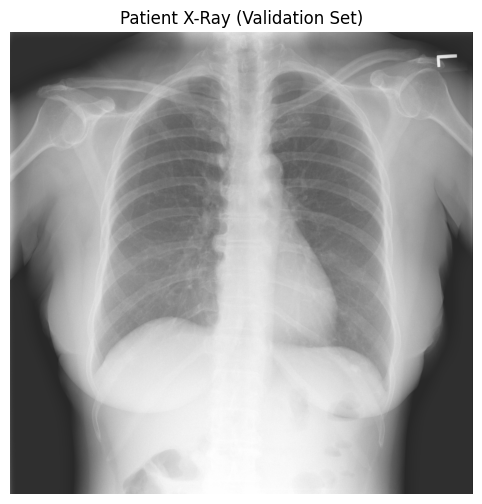


ACTUAL RADIOLOGIST REPORT (Cleaned):
Heart size within normal limits, stable mediastinal and hilar contours. No focal alveolar consolidation, no definite pleural effusion seen. No typical findings of pulmonary edema. No pneumothorax.

AI GENERATED REPORT (Cleaned):
The heart is normal in size and contour. There is no mediastinal widening. The lungs are clear bilaterally. No large pleural effusion or pneumothorax. they are intact. Mild dextro curvature of the thoracic spine, possibly positional. Visualized bony structures are otherwise unremarkable. Unremarkable.


In [32]:
#### After Post-processing Filer applied
import matplotlib.pyplot as plt
import random
import torch
import re
import os
from PIL import Image

print("Extracting a random test X-ray for AI generation...")
model.eval()

# The Perfected Post-Processing Filter
def clean_clinical_text(text):
    clean_text = re.sub(r'\bXXXX\b', '', text)
    clean_text = re.sub(r'(?i)\bthe\s+are\b', 'they are', clean_text)
    clean_text = re.sub(r'\s+\.', '.', clean_text)
    clean_text = re.sub(r'\s+', ' ', clean_text).strip()
    return clean_text

# Pick a random patient from the validation set
test_idx = random.randint(0, len(val_dataset) - 1)
test_sample = val_dataset[test_idx]

pixel_values = test_sample["pixel_values"].unsqueeze(0).to(device)
raw_actual_report = val_text_df.iloc[test_idx]['findings']
img_path = os.path.join(IMG_BASE_DIR, 'images/images_normalized', val_text_df.iloc[test_idx]['filename'])

# Command the AI to generate a strictly constrained report
with torch.no_grad():
    generated_ids = model.generate(
        pixel_values,
        max_length=60,
        min_length=10,
        num_beams=5,
        no_repeat_ngram_size=3,
        repetition_penalty=1.5,
        length_penalty=1.2,
        early_stopping=True
    )

raw_generated_text = tokenizer.decode(generated_ids[0], skip_special_tokens=True)

# Scrub both the real report and the AI report for a clean comparison
clean_actual = clean_clinical_text(raw_actual_report)
clean_generated = clean_clinical_text(raw_generated_text)

# Display the X-ray and the results
image = Image.open(img_path).convert('RGB')
plt.figure(figsize=(6,6))
plt.imshow(image)
plt.axis('off')
plt.title("Patient X-Ray (Validation Set)")
plt.show()

print("\n" + "="*50)
print("ACTUAL RADIOLOGIST REPORT (Cleaned):")
print("="*50)
print(clean_actual)

print("\n" + "="*50)
print("AI GENERATED REPORT (Cleaned):")
print("="*50)
print(clean_generated)

In [33]:
!pip install -q rouge-score nltk

import torch
import re
import nltk
from nltk.translate.bleu_score import corpus_bleu
from rouge_score import rouge_scorer
from tqdm import tqdm

nltk.download('punkt', quiet=True)

print("Booting up the Quantitative Evaluation Engine...")

# The Perfected Post-Processing Filter
def clean_clinical_text(text):
    clean_text = re.sub(r'\bXXXX\b', '', text)
    clean_text = re.sub(r'(?i)\bthe\s+are\b', 'they are', clean_text)
    clean_text = re.sub(r'\s+\.', '.', clean_text)
    clean_text = re.sub(r'\s+', ' ', clean_text).strip()
    return clean_text

# Initialize scorers
scorer = rouge_scorer.RougeScorer(['rouge1', 'rouge2', 'rougeL'], use_stemmer=True)

actual_reports_list = []
generated_reports_list = []

model.eval()

# 500 is the statistical sweet spot for Colab T4 without timing out
EVAL_LIMIT = min(500, len(val_dataset))

print(f"Generating and evaluating {EVAL_LIMIT} clinical reports.")
print("Grab a coffee—this will take roughly 15-25 minutes...")

with torch.no_grad():
    for i in tqdm(range(EVAL_LIMIT), desc="Evaluating"):
        sample = val_dataset[i]
        pixel_values = sample["pixel_values"].unsqueeze(0).to(device)

        # The strict decoding strategy we established
        generated_ids = model.generate(
            pixel_values,
            max_length=60,
            min_length=10,
            num_beams=5,
            no_repeat_ngram_size=3,
            repetition_penalty=1.5,
            length_penalty=1.2,
            early_stopping=True
        )

        raw_generated = tokenizer.decode(generated_ids[0], skip_special_tokens=True)
        raw_actual = val_text_df.iloc[i]['findings']

        # Apply the artifact cleaner
        clean_gen = clean_clinical_text(raw_generated)
        clean_actual = clean_clinical_text(raw_actual)

        generated_reports_list.append(clean_gen)
        # BLEU requires the references to be a list of lists
        actual_reports_list.append([clean_actual.split()])

# Calculate BLEU Score
# We format the generated reports for the BLEU calculator
formatted_predictions = [report.split() for report in generated_reports_list]
bleu_score = corpus_bleu(actual_reports_list, formatted_predictions)

# Calculate ROUGE Scores
rouge1_scores = []
rouge2_scores = []
rougel_scores = []

for actual, generated in zip(val_text_df['findings'].head(EVAL_LIMIT), generated_reports_list):
    clean_actual = clean_clinical_text(actual)
    scores = scorer.score(clean_actual, generated)
    rouge1_scores.append(scores['rouge1'].fmeasure)
    rouge2_scores.append(scores['rouge2'].fmeasure)
    rougel_scores.append(scores['rougeL'].fmeasure)

avg_rouge1 = sum(rouge1_scores) / len(rouge1_scores)
avg_rouge2 = sum(rouge2_scores) / len(rouge2_scores)
avg_rougel = sum(rougel_scores) / len(rougel_scores)

print("\n" + "="*50)
print("PHASE B QUANTITATIVE RESULTS (PROTOTYPE)")
print("="*50)
print(f"BLEU Score:   {bleu_score:.4f} (Exact word overlap)")
print(f"ROUGE-1:      {avg_rouge1:.4f} (Single word recall)")
print(f"ROUGE-2:      {avg_rouge2:.4f} (Two-word phrase recall)")
print(f"ROUGE-L:      {avg_rougel:.4f} (Longest matching sequence)")
print("="*50)

  Preparing metadata (setup.py) ... done
Booting up the Quantitative Evaluation Engine...
Generating and evaluating 331 clinical reports.
Grab a coffee—this will take roughly 15-25 minutes...


Evaluating: 100%|██████████| 331/331 [07:22<00:00,  1.34s/it]



PHASE B QUANTITATIVE RESULTS (PROTOTYPE)
BLEU Score:   0.0671 (Exact word overlap)
ROUGE-1:      0.4008 (Single word recall)
ROUGE-2:      0.1456 (Two-word phrase recall)
ROUGE-L:      0.2811 (Longest matching sequence)
